In [1]:
import random
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras import layers, models
import matplotlib.pyplot as plt

In [2]:
# Load CIFAR-10 dataset
x_train = np.load('cifar-10.npz/x_train.npy')
y_train = np.load('cifar-10.npz/y_train.npy')
x_test = np.load('cifar-10.npz/x_test.npy')
y_test = np.load('cifar-10.npz/y_test.npy')

print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(50000, 32, 32, 3)
(50000, 1)
(10000, 32, 32, 3)
(10000, 1)


In [3]:
# Normalization
x_train = x_train / 255.0
x_test = x_test / 255.0

In [ ]:
# model = models.Sequential

In [4]:
# Define Feedforward Neural Network 

model = models.Sequential([
    layers.Input(shape=(32,32,3)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         786,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 828,490 (3.16 MB)

 Trainable params: 828,490 (3.16 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:


model.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=0.01
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)



In [6]:
# Train the model
history = model.fit(
    x_train, y_train,
    epochs=20,
    validation_split=0.1
)

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.3090 - loss: 1.9246 - val_accuracy: 0.3384 - val_loss: 1.8186
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.3834 - loss: 1.7323 - val_accuracy: 0.3454 - val_loss: 1.8267
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.4142 - loss: 1.6462 - val_accuracy: 0.3666 - val_loss: 1.7667
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4343 - loss: 1.5858 - val_accuracy: 0.4212 - val_loss: 1.6061
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.4540 - loss: 1.5419 - val_accuracy: 0.4052 - val_loss: 1.6466
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4667 - loss: 1.5003 - val_accuracy: 0.4350 - val_loss: 1.5873
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.4770 - loss: 1.4682 - val_accuracy: 0.4182 - val_loss: 1.6132
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4904 - loss: 1.

In [7]:

# Evaluate training data
train_loss, train_acc = model.evaluate(x_train, y_train, verbose=0)

# Evaluate testing data
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

# Print results
print("Training Accuracy:", train_acc * 100, "%")
print("Training Loss:", train_loss)

print("Testing Accuracy:", test_acc * 100, "%")
print("Testing Loss:", test_loss)


Training Accuracy: 57.204002141952515 %
Training Loss: 1.2085590362548828
Testing Accuracy: 50.48999786376953 %
Testing Loss: 1.4203331470489502


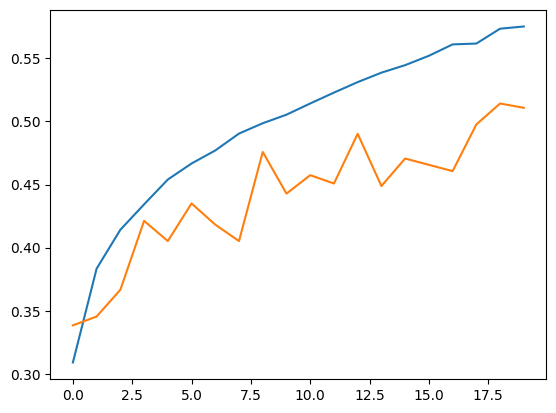

In [8]:
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')

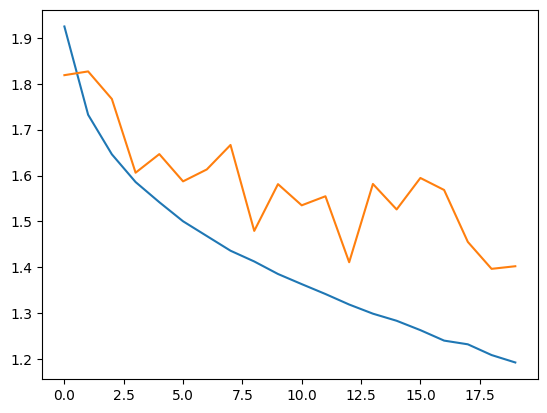

In [9]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')